In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn import datasets

In [2]:
df = pd.read_csv("box_cox.csv")
df.head()

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X99991,X99992,X99993,X99994,X99995,X99996,X99997,X99998,X99999,X100000
1,0.200000,0.200000,0.200000,0.200000,0.200000,0.200000,0.200000,0.200000,0.200000,0.200000,...,0.200000,0.200000,0.200000,0.200000,0.200000,0.200000,0.200000,0.200000,0.200000,0.200000
2,0.250000,0.250000,0.250000,0.250000,0.250000,0.250000,0.250000,0.250000,0.250000,0.250000,...,0.250000,0.250000,0.250000,0.250000,0.250000,0.250000,0.250000,0.250000,0.250000,0.250000
3,0.333331,0.333331,0.333331,0.333331,0.333332,0.333332,0.333330,0.333331,0.333329,0.333331,...,0.333332,0.333331,0.333331,0.333331,0.333329,0.333326,0.333330,0.333331,0.333329,0.333332
4,0.499822,0.499800,0.499815,0.499800,0.499846,0.499861,0.499783,0.499792,0.499717,0.499792,...,0.499846,0.499835,0.499829,0.499841,0.499717,0.499592,0.499753,0.499815,0.499742,0.499846
5,0.981132,0.980000,0.980769,0.980000,0.982456,0.983333,0.979167,0.979592,0.976190,0.979592,...,0.982456,0.981818,0.981481,0.982143,0.976190,0.971429,0.977778,0.980769,0.977273,0.982456


In [3]:
df.mean(axis=1)

1     2.000000e-01
2     2.500000e-01
3     3.333303e-01
4     4.997867e-01
5     9.795705e-01
6              NaN
7     4.897608e+01
8     1.273400e+03
9     4.413044e+04
10    1.751769e+06
dtype: float64

In [4]:
dft = df.transpose()

In [5]:
dft.head()

,1,2,3,4,5,6,7,8,9,10
X1,0.2,0.25,0.333331,0.499822,0.981132,NaN,52.0,1404.0,49625.333333,1972620.00
X2,0.2,0.25,0.333331,0.499800,0.980000,NaN,49.0,1249.5,41666.333333,1562499.75
X3,0.2,0.25,0.333331,0.499815,0.980769,NaN,51.0,1351.5,46869.000000,1827903.75
X4,0.2,0.25,0.333331,0.499800,0.980000,NaN,49.0,1249.5,41666.333333,1562499.75
X5,0.2,0.25,0.333332,0.499846,0.982456,NaN,56.0,1624.0,61730.666667,2639000.00


In [6]:
from sklearn.linear_model import LinearRegression

In [7]:
df = datasets.load_iris

In [8]:
obs = np.random.normal(50,2,100)

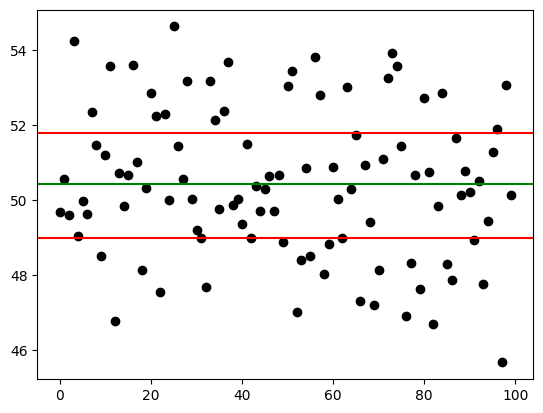

In [9]:
x_axis = range(100)
plt.scatter(x_axis,obs,color="black")
plt.axhline(pd.Series(obs).quantile(.75),color="red")
plt.axhline(obs.mean(),color="green")
plt.axhline(pd.Series(obs).quantile(.25),color="red")

In [10]:
x = np.random.normal(0,1,100)

In [11]:
xx = x.reshape(10,10)

In [12]:
xx

array([[-0.33975507, -0.13841109, -1.71017664, -1.35839167, -0.4498115 ,
        -0.52175638,  1.31346251, -0.61707182, -0.3881099 , -1.18537253],
       [ 0.19577061, -0.45346858,  0.29173582,  0.21359448, -0.50285215,
         2.44542916, -0.26201621, -0.47786586, -1.89985226,  0.00802604],
       [-1.1551344 , -0.03705307,  1.58453339,  0.94086016, -1.29398073,
         1.00916756, -0.66017479,  0.23579913, -0.49302387, -1.1813641 ],
       [ 0.14697142, -1.49172315, -0.38696781,  0.17165713,  1.02182563,
         2.1437286 ,  0.17320041, -0.46615172,  0.38287648,  1.1842852 ],
       [-0.49563022, -1.70486129,  0.68708718, -0.21723731,  0.42397788,
         0.29210071, -0.02066513,  0.58864853, -0.05075292, -1.53502504],
       [ 0.35682883,  1.28442857,  1.04228999, -0.36875077,  0.08913149,
        -1.02775094, -1.53393864,  0.930547  , -0.18355748,  0.17634648],
       [ 0.07708845, -0.27614342, -0.05600461,  0.31259313, -0.04581434,
         0.67942223, -0.5358011 , -0.25727191

In [13]:
totals = []
for i in range(10):
    sums = 0
    for j in range(10):
        sums += np.abs(xx[i][j])
    totals.append(sums/10)

In [14]:
totals

[0.8022319111291718,
 0.6750611179374785,
 0.859109119842298,
 0.7569387548283,
 0.6015986209481012,
 0.6993570192518132,
 0.47078127485159876,
 0.8750326172519329,
 0.8560443161124163,
 0.7261097533754589]

In [15]:
# def summing(ls):
#     return sum(ls)
# pd.Series(totals).apply(summing)

In [16]:
def absMean(ls):
    avg = sum(ls)/len(ls)
    return avg

def absStd(ls):
    avg = sum(np.abs(ls))/len(ls)
    stds = np.sqrt(sum(ls-avg)**2)/(len(ls)-1)
    return stds


In [17]:
import warnings
warnings.filterwarnings('ignore')

In [18]:
absMean(totals)

0.732226450552857

In [19]:
absStd(totals)

6.1679056923619804e-18

In [20]:
np.abs(np.random.normal(0,1,100)).mean()

0.7544695560190496

In [21]:
x1 = np.random.random_integers(0,100,10)
x2 = np.random.random_integers(1000,10000,10)
x3 = np.random.random_integers(1000000,1000000000,10)

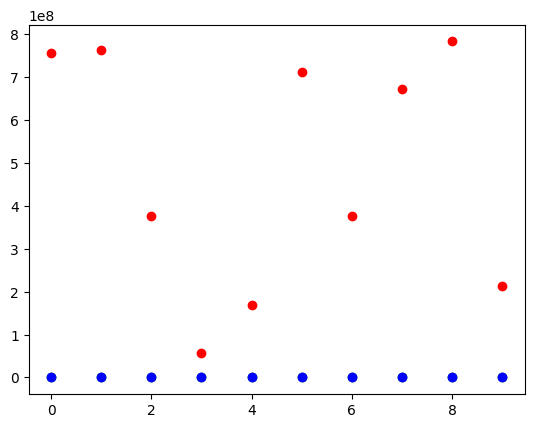

In [22]:
l = range(len(x1))
plt.scatter(l,x1,color="green")
plt.scatter(l,x2,color="blue")
plt.scatter(l,x3,color="red")


In [23]:
d =np.random.random_integers(10,1542455,10)

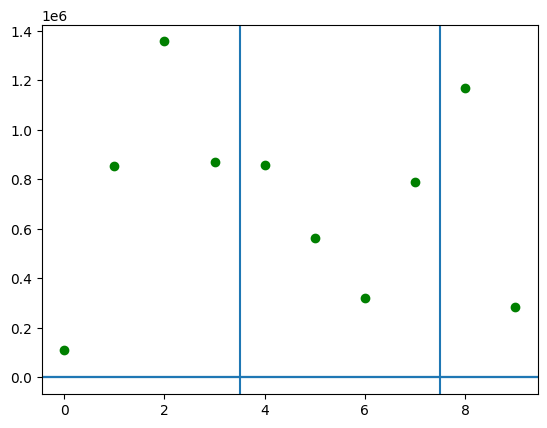

In [24]:
plt.scatter(range(len(d)),d,color="green")
plt.axhline(1)
plt.axhline(.4)
plt.axhline(.2)
plt.axvline(7.5)
plt.axvline(3.5)

In [26]:
obs2 = np.random.normal(0,1,1000)

In [27]:
sds = obs2.std()

In [32]:
pd.Series(obs2).loc[obs2 > sds].size

159

In [34]:
pd.Series(obs2).loc[obs2 < -sds].size

146

In [35]:
pd.Series(obs2).loc[obs2 > sds].size+pd.Series(obs2).loc[obs2 < -sds].size

305

In [38]:
newSeries = pd.Series(obs2).drop([obs2 > 3*sds or obs2 < -3*sds],axis=0)

ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

In [37]:
newSeries = pd.Series(obs2)

In [39]:
ls = np.arange(10)

In [40]:
ls

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [41]:
s = pd.Series(ls)

In [42]:
s

0    0
1    1
2    2
3    3
4    4
5    5
6    6
7    7
8    8
9    9
dtype: int32

In [43]:
s['X'] = s[0]

In [44]:
s

0    0
1    1
2    2
3    3
4    4
5    5
6    6
7    7
8    8
9    9
X    0
dtype: int32

In [45]:
s.loc[s>5]

6    6
7    7
8    8
9    9
dtype: int32

In [47]:
s.drop(s > 5,axis=0)

2    2
3    3
4    4
5    5
6    6
7    7
8    8
9    9
X    0
dtype: int32

In [48]:
s

0    0
1    1
2    2
3    3
4    4
5    5
6    6
7    7
8    8
9    9
X    0
dtype: int32

In [49]:
df = pd.DataFrame(ls)

In [50]:
df

,0
0,0
1,1
2,2
3,3
4,4
5,5
6,6
7,7
8,8
9,9


In [62]:
df2 = df.drop(df > 5,axis=0)

In [63]:
df2

,0
1,1
2,2
3,3
4,4
5,5
6,6
7,7
8,8
9,9


In [65]:
xx = pd.DataFrame(np.random.normal(0,1,100).reshape(10,10))

In [70]:
xx.rename_axis(['X1','X2','X3','X4','X5','X6','X7','X8','X9','X10'])

ValueError: Length of new names must be 1, got 10

In [71]:
xx

,0,1,2,3,4,5,6,7,8,9
0,-0.649215,-0.205059,0.495454,-0.736641,-1.662300,-0.696847,-0.112270,1.114582,-0.290149,1.138263
1,1.062809,1.021105,1.294810,-0.536164,1.948749,-0.285557,-0.392822,-1.484751,0.886946,1.502507
2,1.590385,-0.566340,-1.041768,-0.571648,-0.462412,0.032628,2.077501,1.145591,-0.207155,1.012784
3,0.135888,1.881117,-0.194880,0.592813,0.265988,-1.474801,-0.017171,0.178169,1.149517,-1.936199
4,0.441563,-0.832896,0.012447,0.089466,-0.176703,0.768537,1.438738,1.729772,2.588511,-0.146472
5,-0.831375,0.978917,0.463597,-0.234041,-1.183792,0.960836,-0.881604,-1.177391,-0.870283,0.110511
6,1.297119,-1.864090,0.837359,2.420483,-1.493082,-0.038266,0.560286,-1.203419,-0.545822,-0.052565
7,0.147202,1.785189,-0.564122,-1.196749,-0.204475,1.130097,0.108192,0.006688,0.949270,-0.781148
8,-0.573229,0.987989,0.600961,1.018897,0.023965,-0.659718,1.338965,1.672183,-1.225804,-0.783055
9,3.070397,0.640597,1.027477,-0.258830,-0.312481,2.527899,0.835030,1.614208,-0.449930,0.090052


In [73]:
xx.rename_axis(range(0,9)['X1','X2','X3','X4','X5','X6','X7','X8','X9','X10'],axis=1)

ValueError: For argument "inplace" expected type bool, received type list.